<a href="https://colab.research.google.com/github/placide220/ML_Pipeline/blob/shami/analytical_questions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analytical Questions: Household Power Consumption
**Part 2 (analytical questions + visualizations)**

Target: `Global_active_power` (kW). Each question below has: why it matters, code, one plot, and an interpretation cell for *your own* findings.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from time_series_features import add_lags, add_rolling

plt.rcParams["figure.figsize"] = (11, 4)
TARGET = "Global_active_power"

## Load data
TEMPORARY: loads the raw file and resamples to hourly so you can start now.
**Replace this cell with Placide's cleaned file** once he shares it, and note his resampling and missing-value choices in your report.

In [7]:
# TODO: swap for Placide's cleaned data, e.g. pd.read_csv("data/clean.csv", index_col=0, parse_dates=True)
files = ["train.csv", "validation.csv", "test.csv"]
df_list = [pd.read_csv(f, sep=",", na_values=["?"], low_memory=False) for f in files]
# raw = pd.concat(df_list).sort_index()
raw = pd.concat(df_list, ignore_index=True)
raw["datetime"] = pd.to_datetime(raw["Datetime"])
raw = raw.set_index("datetime").drop(columns=["Datetime"]).sort_index()

# raw["datetime"] = pd.to_datetime(raw["Datetime"])
# raw = raw.set_index("datetime").drop(columns=["Datetime"], errors="ignore")

df = raw.resample("h").mean()
df = df.interpolate(method="time", limit=6)   # placeholder: match Placide's method
print(df.shape, df.index.min(), df.index.max())
df.head()

(14137, 9) 2006-12-16 17:00:00 2008-07-27 17:00:00


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Unmetered_Wh,Imputed
datetime,,,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111,52.992589,0.0
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667,36.953327,0.0
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333,38.553893,0.0
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333,37.692777,0.0
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667,33.307782,0.0


In [8]:
df = raw.resample("h").mean()
print(df.isna().sum().sum())
print(df["Imputed"].describe())
print((df["Imputed"] > 0).mean())   # share of hours that contain imputed minutes

0
count    14137.000000
mean         0.004651
std          0.067011
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: Imputed, dtype: float64
0.006790691094291575


## Q1. Is there a long-term trend in consumption?
**Why it matters:** a trend means the series is non-stationary, which affects model choice and whether differencing is needed.

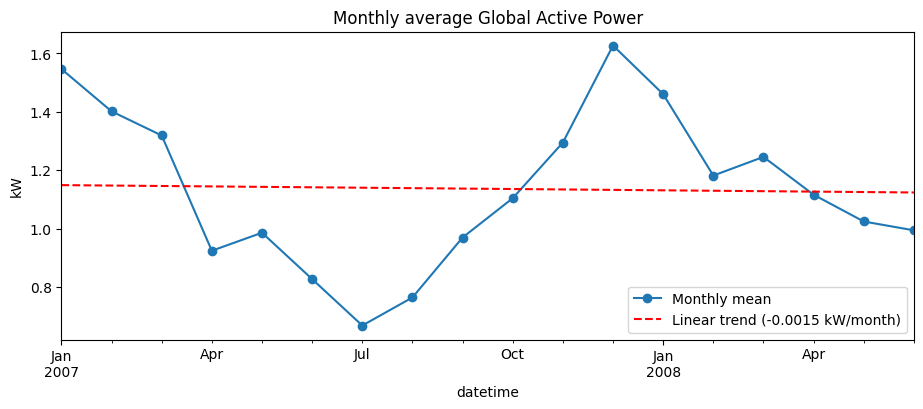

In [9]:
# Drop the partial first/last months so they don't distort the trend
monthly = df[TARGET].resample("MS").mean().loc["2007-01":"2008-06"]

x = np.arange(len(monthly))
slope, intercept = np.polyfit(x, monthly.values, 1)

ax = monthly.plot(marker="o", label="Monthly mean")
pd.Series(slope * x + intercept, index=monthly.index).plot(ax=ax, style="r--", label=f"Linear trend ({slope:.4f} kW/month)")
ax.set_title("Monthly average Global Active Power")
ax.set_ylabel("kW"); ax.legend(); plt.show()

**Interpretation:**
- Direction and size of the trend?
The trend is slightly downward as time moves, about -0.0015 kW/month (roughly -0.03 kW over the 18 months), which is very small.
- Is the line a good summary, or is seasonality dominating?
Given how short the period is, the trend line is a poor summary because seasonality dominates. The monthly average swings from about 0.67 kW to 1.63 kW, which is much bigger than the trend. The small negative slope may also come from the data starting in winter and ending in summer.
- What does this mean for modelling?
For the model this means there is no clear long-term trend, but it needs seasonal or calendar features.


## Q2. What does a typical day look like, and do weekdays differ from weekends?
**Why it matters:** hour-of-day and day-of-week effects are strong predictors; they justify calendar features.

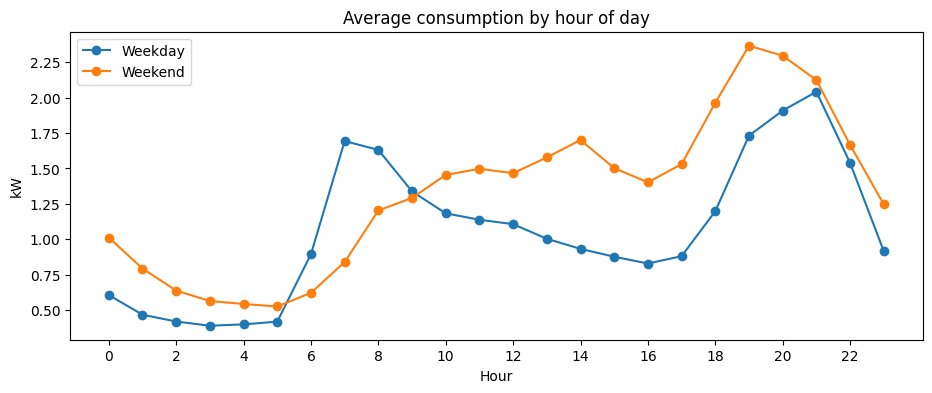

In [10]:
tmp = df[[TARGET]].copy()
tmp["hour"] = tmp.index.hour
tmp["is_weekend"] = tmp.index.dayofweek >= 5

profile = tmp.groupby(["hour", "is_weekend"])[TARGET].mean().unstack()
profile.columns = ["Weekday", "Weekend"]
ax = profile.plot(marker="o")
ax.set_title("Average consumption by hour of day")
ax.set_xlabel("Hour"); ax.set_ylabel("kW"); ax.set_xticks(range(0, 24, 2)); plt.show()

**Interpretation:**
- Peak hours and quiet hours?
On weekdays there are 2 peaks, one around 7-8 (about 1.7 kW) and another one around 20-21 (about 2.05 kW). The quietest hours are around 3-4 (about 0.4 kW). On weekends there is an upward trend from the early hours, with a small peak at 14 (about 1.7 kW), then a small dip, and it truly peaks at 19-20 (about 2.35 kW).
- How do weekend and weekday shapes differ, and what household behaviour could explain it?
I think on weekdays the morning peak is when people are getting ready to go to work, with kettles, irons and other home appliances being used. In the evening it's the same thing: everyone is home from work and making dinner, all the lights in the house are on, and the TV as well.
The weekend shows that people probably sleep in and wake up around brunch hours, then relax in the early afternoon watching movies. The bigger peak in the evening also suggests more is going on, like preparing dinner, watching TV or having friends over.

## Q3. Is there yearly seasonality?
**Why it matters:** if winter and summer differ consistently, month or season should be a model feature.

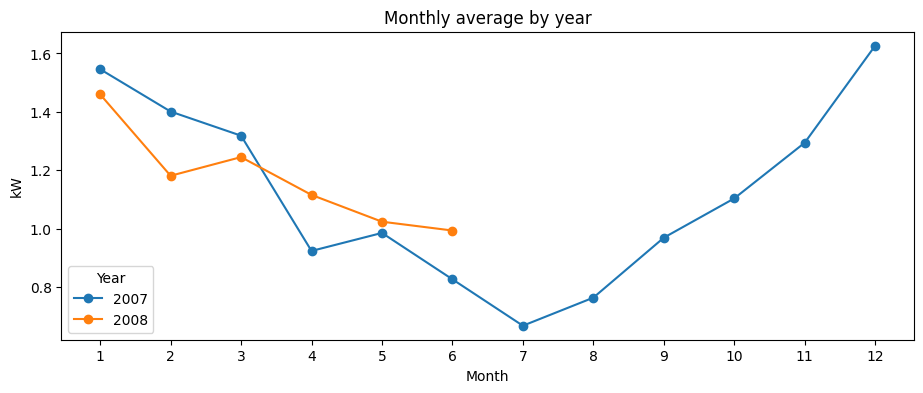

In [11]:
m = df[TARGET].resample("MS").mean().loc["2007-01":"2008-06"]   # full years only
season = m.groupby([m.index.year, m.index.month]).mean().unstack(0)
ax = season.plot(marker="o")
ax.set_title("Monthly average by year")
ax.set_xlabel("Month"); ax.set_ylabel("kW"); ax.set_xticks(range(1, 13)); ax.legend(title="Year"); plt.show()

**Interpretation (write your own):**
- Which months are highest and lowest? Do the years follow the same shape?
December to January are the highest months given that these are cold it makes sence and the lowest month is July-August in the middle of summer which suggest that people are mostly outside.
I think the years might follow thw same shape tha small snippet we saw of 2008 it show that it followed the trend with a slight overall increase.
- Likely cause (heating, holidays, daylight)? Anything odd, such as an August dip?
I think the causes are the weather seasons which shows that people are inside in winter and very outside in the summer.

## Q4. Lag effects: how much does the past predict the present? (required: lagged features)
**Why it matters:** strong autocorrelation at specific lags tells us which lagged features to feed the model.

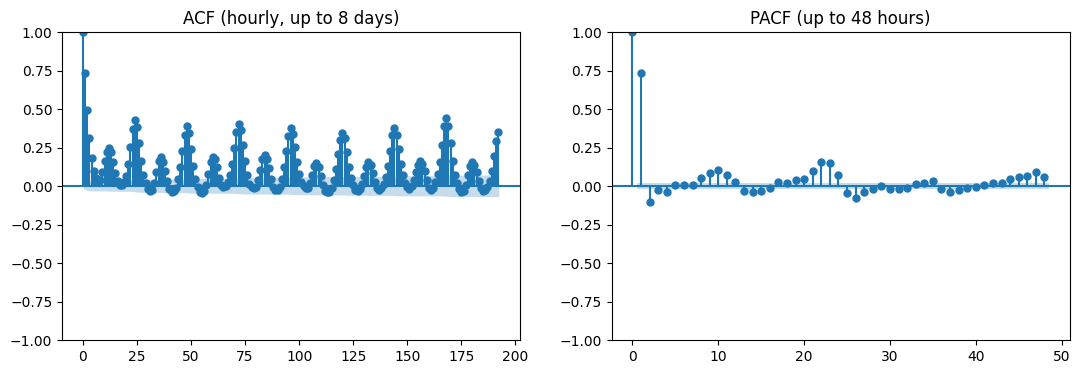

Global_active_power           1.000
Global_active_power_lag1      0.735
Global_active_power_lag24     0.431
Global_active_power_lag168    0.455
Name: Global_active_power, dtype: float64


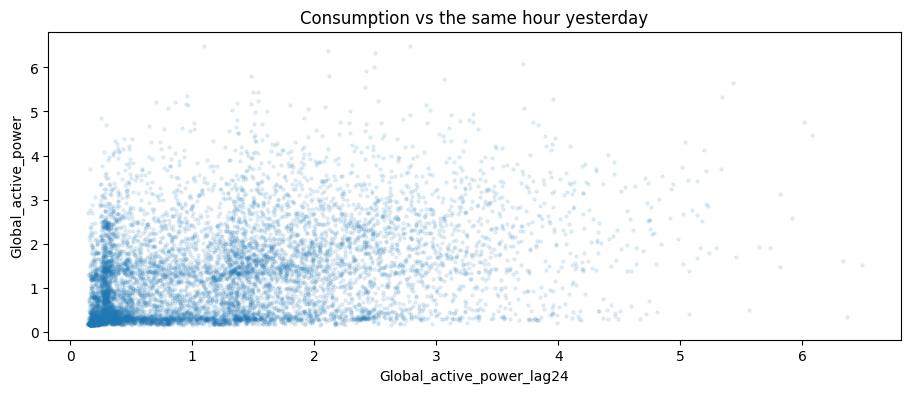

In [12]:
train_df = df.loc[:"2008-02-02"]   # training period only

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(train_df[TARGET].dropna(), lags=24 * 8, ax=axes[0]); axes[0].set_title("ACF (hourly, up to 8 days)")
plot_pacf(train_df[TARGET].dropna(), lags=48, ax=axes[1], method="ywm"); axes[1].set_title("PACF (up to 48 hours)")
plt.show()

lagged = add_lags(train_df[[TARGET]], TARGET, [1, 24, 168])
print(lagged.corr()[TARGET].round(3))

ax = lagged.plot.scatter(x=f"{TARGET}_lag24", y=TARGET, alpha=0.1, s=5)
ax.set_title("Consumption vs the same hour yesterday"); plt.show()

**Interpretation:**
- ***Which lags have the highest correlation (1h, 24h, 168h)? Why those?***
1hour lag have the highest correlation by far(0.735), this can be explained consumption changes gradualu hour to hour which is better for prediction, lag 128 came second with (0.455) and then lag 24h with  (0.431).
- ***What does the ACF pattern say about daily and weekly cycles?***
The ACF plot shows that lag 168h is slightly better than lag 24h whcih can be explained by having days of the week which have the same pattern/behaviour so it performed better than lag 24h becasue predicting a Monday from Sundays data isn't as good as using the last week mMonday because days are diffrent as we saw
- ***Which lags will you recommend for the model?***
I would recommend all lag 1h, 24h, and 168h as candidate features for the model, I'd also recommend tryin lag 2h sin the PACF plot showed a small negative value.

## Q5. Does a moving average reveal structure hidden by noise? (required: moving averages)
**Why it matters:** rolling means smooth noise and make good model features.

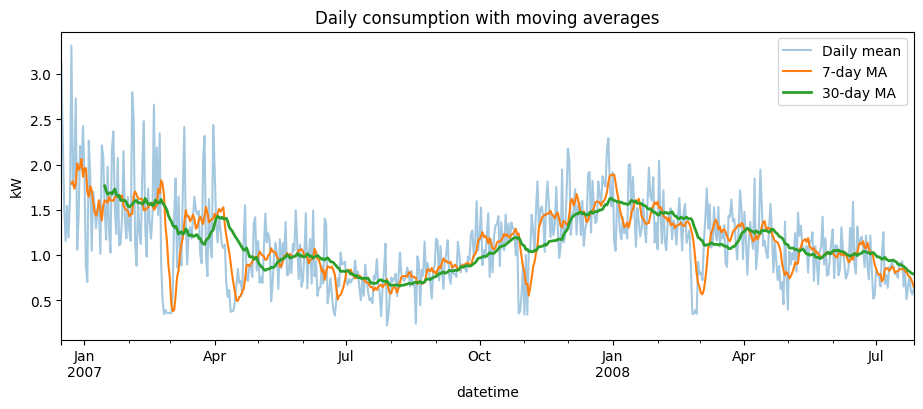

In [13]:
daily = df[[TARGET]].resample("D").mean()
daily = add_rolling(daily, TARGET, [7, 30])

ax = daily[TARGET].plot(alpha=0.4, label="Daily mean")
daily[f"{TARGET}_roll7"].plot(ax=ax, label="7-day MA")
daily[f"{TARGET}_roll30"].plot(ax=ax, lw=2, label="30-day MA")
ax.set_title("Daily consumption with moving averages"); ax.set_ylabel("kW"); ax.legend(); plt.show()

**Interpretation:**
- ***What does the 30-day line show that the raw series hides?***
The 30-day line shows the seasonal trend while the daily mean moves a lot from 0.3 - 3.3Kw. This make it difficult to read the pattern from it alone the 30-day smoothes it out.
- ***7-day vs 30-day: what does each capture?***
The 7-day smooths out day to day noise but still shows week scale movements, the 30-day shows seasonal trend over the year, it show low consumption in summer and high in winter/cold months.
- ***Any gaps or flat sections (missing data) visible? How might they affect the result?***
There are no gaps visible and there's no missing dat after imputation, and the low consumption data have 0 imputed data. The 7-day shows some hard dips that only the weekly shows wich can be possibly explained by people not being home.round Feb 2007, around Oct to Nov 2007 and around Feb 2008, daily consumption falls to about 0.35 kW for several days. The 30-day barely moves. Moving Averages lags behind, the 30-day MA starts after a month in because it needs 30 days history.

In [14]:
dip_days = daily[daily[TARGET] < 0.5].index
print(df.loc[df.index.normalize().isin(dip_days), "Imputed"].mean())

0.0
